# Q8: Interacting with Web APIs

**Problem Statement:** Analyzing Weather Data from OpenWeatherMap API

In [1]:
# Request the API when a key is available; otherwise use the offline sample.
import json
import os
import requests
import pandas as pd
import matplotlib.pyplot as plt

api_key = os.getenv("OPENWEATHER_API_KEY")
if api_key:
    try:
        response = requests.get(
            "https://api.openweathermap.org/data/2.5/forecast",
            params={"q": "Pune,IN", "appid": api_key, "units": "metric"},
            timeout=20,
        )
        response.raise_for_status()
        weather_json = response.json()
        print("Live OpenWeatherMap forecast loaded.")
    except requests.RequestException as error:
        print("Live request failed; using local sample:", error)
        weather_json = json.loads(open("OpenWeatherMap_sample.json", encoding="utf-8").read())
else:
    print("No OPENWEATHER_API_KEY set; using synthetic local sample.")
    weather_json = json.loads(open("OpenWeatherMap_sample.json", encoding="utf-8").read())
print("Location:", weather_json["city"]["name"], "records:", len(weather_json["list"]))


No OPENWEATHER_API_KEY set; using synthetic local sample.
Location: Pune records: 40


In [2]:
# Extract temperature, humidity, wind and precipitation from each response item.
rows = []
for item in weather_json["list"]:
    rows.append({
        "time": pd.to_datetime(item["dt"], unit="s", utc=True),
        "temperature_c": item.get("main", {}).get("temp"),
        "humidity_pct": item.get("main", {}).get("humidity"),
        "wind_m_s": item.get("wind", {}).get("speed"),
        "rain_mm": item.get("rain", {}).get("3h", 0),
    })
weather = pd.DataFrame(rows).sort_values("time")
numeric = ["temperature_c", "humidity_pct", "wind_m_s", "rain_mm"]
weather[numeric] = weather[numeric].apply(pd.to_numeric, errors="coerce")
weather[numeric] = weather[numeric].interpolate(limit_direction="both").fillna(0)
print(weather.head().to_string(index=False))
print("Missing measurements:", int(weather[numeric].isna().sum().sum()))


                     time  temperature_c  humidity_pct  wind_m_s  rain_mm
2025-04-01 00:00:00+00:00           22.9            66       2.3      2.2
2025-04-01 03:00:00+00:00           27.9            55       5.0      0.0
2025-04-01 06:00:00+00:00           30.2            52       3.5      0.0
2025-04-01 09:00:00+00:00           26.9            54       2.0      0.0
2025-04-01 12:00:00+00:00           25.3            73       4.7      0.0
Missing measurements: 0


In [3]:
# Model daily summaries and inspect changes over the forecast period.
daily = weather.set_index("time").resample("D").agg({
    "temperature_c": ["mean", "min", "max"],
    "humidity_pct": "mean",
    "wind_m_s": "mean",
    "rain_mm": "sum",
})
daily.columns = ["temp_mean", "temp_min", "temp_max", "humidity_mean", "wind_mean", "rain_total"]
print(daily.round(2).to_string())
print("Overall temperature range:", weather["temperature_c"].min(), "to", weather["temperature_c"].max(), "°C")


                           temp_mean  temp_min  temp_max  humidity_mean  wind_mean  rain_total
time                                                                                          
2025-04-01 00:00:00+00:00      24.40      19.0      30.2          65.00       3.00         6.0
2025-04-02 00:00:00+00:00      25.40      21.1      30.1          66.75       3.26         1.1
2025-04-03 00:00:00+00:00      25.14      20.6      29.9          62.62       2.74         3.3
2025-04-04 00:00:00+00:00      24.74      19.3      30.2          65.00       3.12         3.2
2025-04-05 00:00:00+00:00      24.46      18.6      28.9          65.75       2.62         3.3
Overall temperature range: 18.6 to 30.2 °C


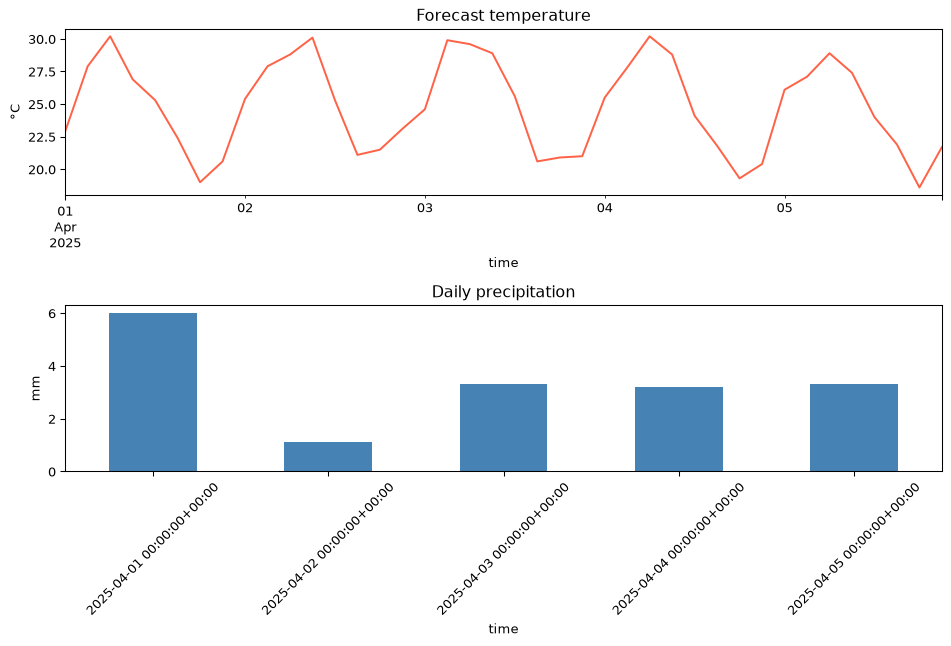

In [4]:
# Plot weather trends and daily rainfall.
fig, axes = plt.subplots(2, 1, figsize=(10, 7))
weather.plot(x="time", y="temperature_c", ax=axes[0], legend=False, color="tomato")
axes[0].set_title("Forecast temperature")
axes[0].set_ylabel("°C")
daily["rain_total"].plot.bar(ax=axes[1], color="steelblue", title="Daily precipitation")
axes[1].set_ylabel("mm")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


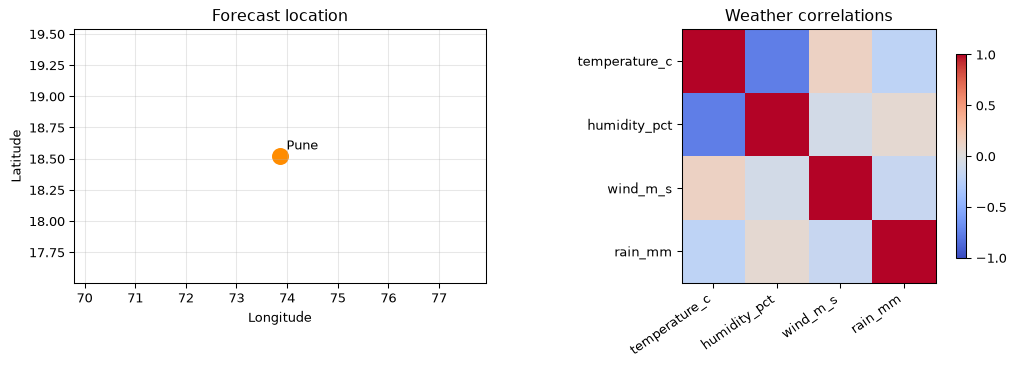

In [5]:
# Show the location, then visualize correlations between weather variables.
coords = weather_json["city"]["coord"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(coords["lon"], coords["lat"], s=140, color="darkorange")
axes[0].annotate(weather_json["city"]["name"], (coords["lon"], coords["lat"]), xytext=(5, 5), textcoords="offset points")
axes[0].set(xlabel="Longitude", ylabel="Latitude", title="Forecast location")
axes[0].grid(alpha=0.3)
correlation = weather[numeric].corr()
image = axes[1].imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
axes[1].set_xticks(range(len(numeric)), numeric, rotation=35, ha="right")
axes[1].set_yticks(range(len(numeric)), numeric)
axes[1].set_title("Weather correlations")
fig.colorbar(image, ax=axes[1], shrink=0.8)
plt.tight_layout()
plt.show()
